In [ ]:
pip install langchain_google_genai

In [ ]:
from typing import TypedDict , List , Literal
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.prompts import ChatPromptTemplate
from pydantic import BaseModel , Field
from langgraph.graph import StateGraph, START, END

In [ ]:
writer_prompt = ChatPromptTemplate.from_messages([
    ("system", """You are a professional content writer.
Write clear and engaging content following the user's requirements.
If a previous draft and feedback are provided, revise and improve the draft based on that feedback.

Previous Draft: {draft}
Critic Feedback: {feedback}"""),
    ("human", "Write content about: {topic}")
])

In [ ]:
criticer_prompt=ChatPromptTemplate.from_messages([
    ("human" , "read the following post : {post} and evaluate it")
])

In [ ]:
class PostState(TypedDict):
  user_query:str
  draft: str
  iteration : int
  max_iteration : int
  quality_score : int
  issues:List[str]
  decision:Literal['approved','needs_revision']

In [ ]:
class PostReviewSchema(BaseModel):
  quality_score : int=Field(ge=0,le=10,description="post quality score from 0 to 10")
  issues:List[str]=Field(description="list of issues and recommendations to enhance the post")
  decision:Literal['approved','needs_revision']=Field(...,description="Final decision based on the code quality.")


In [ ]:
llm = ChatGoogleGenerativeAI(
    model="gemini-3.1-flash-lite",
    google_api_key=os.environ['google_api_key']
)

In [ ]:
def writer_node(state: PostState) -> dict:
    messages = writer_prompt.invoke({
        "topic": state["user_query"],
        "draft": state.get("draft", "No draft yet."),
        "feedback": state.get("issues", "No feedback yet.")
    })
    response = llm.invoke(messages)
    return {"draft": response.text}

In [ ]:
def critical_node(state : PostState)->dict:
  current_iter = state["iteration"] + 1
  structured_llm=llm.with_structured_output(PostReviewSchema)
  messages=criticer_prompt.invoke({
      "post":state['draft']
  })
  response=structured_llm.invoke(messages)
  return {
    "quality_score": response.quality_score,
    "issues": response.issues,
    "decision": response.decision,
    "iteration":current_iter
  }


In [ ]:
def quality_gate_router(state:PostState)->Literal['approved','needs_revision']:
  if state['iteration']>state['max_iteration']:
    return 'approved'
  if state['quality_score'] < 8:
    return 'needs_revision'
  return 'approved'

In [ ]:
builder=StateGraph(PostState)

In [ ]:
builder.add_node("writer",writer_node)
builder.add_node("critical",critical_node)

In [ ]:
builder.add_edge(START,"writer")
builder.add_edge("writer","critical")
builder.add_conditional_edges(
    "critical",
    quality_gate_router,
    {
        'approved':END,
        "needs_revision":"writer"
    }
)

In [ ]:
graph=builder.compile()

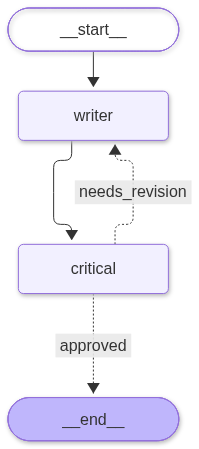

In [ ]:
graph

In [ ]:
graph.invoke({
    'user_query' :"""
    i have done a 6 months internhsip in orascom company as an ai engineer i built a supervised machine learning projects and a production chatbot with rag system.
    gained alot of experience and working in a production environment so i want to publish a post in linkedin to talk about this experience
    """,
    "iteration": 0,
    "max_iteration":5
})

{'user_query': '\n    i have done a 6 months internhsip in orascom company as an ai engineer i built a supervised machine learning projects and a production chatbot with rag system.\n    gained alot of experience and working in a production environment so i want to publish a post in linkedin to talk about this experience\n    ',
 'draft': AIMessage(content=[{'type': 'text', 'text': 'Here are three options for your LinkedIn post, depending on the "vibe" you want to project.\n\n### Option 1: Professional & Impactful (Best for recruiters)\n**Headline:** Reflecting on an incredible 6 months as an AI Engineering Intern at Orascom.\n\nI am excited to share that I have successfully completed my 6-month internship at Orascom! This journey has been transformative, taking me from theory to real-world production impact.\n\nDuring my time here, I had the privilege of working on cutting-edge AI solutions:\n🔹 **Supervised Machine Learning:** Developed and fine-tuned models to solve complex business 